## THIS IS THE EDA AND HYPOTHESIS ANALYSIS PROJECT OF FINANCIAL DATA.

- In this project we will load messy data, Perform basic cleaning checks( duplicates, nulls, formatting errors) and prepare it for EDA Analysis.
- I will visualize and formulate key business insights/ questions that the data should answer
- I will run statistical hypothesis tests to confirm whethere there is relationships betweens different features
- I will analyse the variance and Correlation between theh features.
- I will perform Data preprocessing and modeling to predict the target.


In [3]:
# Import important libraries

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import chi2_contingency, kruskal
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

from sklearn.svm import SVC




In [10]:
import subprocess
import sys

# Load the financial data set ( excel file)
# Load the financial data set (excel file)
try:
    financial_df = pd.read_excel(
        r"C:\Users\USER\Documents\Financial_well_being\Data_raw\finaccess2024_datasprint.xlsx",
        engine="openpyxl"
    )
except ImportError:

    subprocess.check_call([sys.executable, "-m", "pip", "install", "openpyxl"])
    financial_df = pd.read_excel(
        r"C:\Users\USER\Documents\Financial_well_being\Data_raw\finaccess2024_datasprint.xlsx",
        engine="openpyxl"
    )

### Checking the structure of our data set

In [11]:
pd.set_option("display.max_colwidth", None) #This ensures we can view all the columns in the dataset.

In [12]:
financial_df.head(10)


,county,location_type,Sex,Age,household_size,education_level,marital_status,monthly_income,Savings_formal,Savings_informal,...,nfhi_11,nfhi_12,nfhi_13,accessto_13k_1month,not_difficult,financial_status,fl_score,prodsum1,barriers_bank,has_disability
0,Garissa,Urban,Female,26-35,5,Completed technical training after secondary school,Married/Living with partner,30000,Non-usage,Non-usage,...,Yes,Yes,Yes,Yes,No,Stayed the same,All correct,3,NaN,Without Disability
1,Garissa,Urban,Female,Above 55,11,"""None """,Married/Living with partner,10000,Non-usage,Non-usage,...,No,No,Yes,No,No,Worsened,Two correct,1,Affordability,Without Disability
2,Busia,Urban,Female,26-35,2,"""Primary completed""",Divorced/separated,3000,Usage,Usage,...,Yes,No,No,No,No,Improved,All correct,5,Affordability,Without Disability
3,Kiambu,Urban,Male,18-25,1,"""Some secondary""",Single/Never Married,10000,Usage,Non-usage,...,No,No,No,Yes,No,Improved,All correct,4,Affordability,Without Disability
4,Murang'a,Urban,Female,18-25,1,Some technical training after secondary school,Single/Never Married,10000,Usage,Non-usage,...,Yes,Yes,Yes,Yes,Yes,Improved,All correct,5,NaN,Without Disability
5,Kilifi,Rural,Female,Above 55,3,"""Secondary completed """,Married/Living with partner,4000,Non-usage,Non-usage,...,No,Yes,No,No,No,Worsened,All correct,2,Affordability,Without Disability
6,Meru,Rural,Female,36-45,6,"""Some primary """,Single/Never Married,1000,Non-usage,Usage,...,Yes,No,No,No,No,Stayed the same,All correct,4,Affordability,Without Disability
7,Kilifi,Rural,Male,36-45,7,"""Some primary """,Married/Living with partner,8500,Non-usage,Non-usage,...,No,Yes,Yes,No,No,Worsened,One correct,2,Affordability,Without Disability
8,Kisumu,Urban,Female,26-35,4,"""Primary completed""",Married/Living with partner,1500,Usage,Non-usage,...,Yes,Yes,No,Yes,No,Worsened,Two correct,3,Affordability,Without Disability
9,Baringo,Urban,Male,26-35,1,"""Secondary completed """,Married/Living with partner,6500,Usage,Non-usage,...,No,No,No,Yes,No,Improved,All correct,12,NaN,Without Disability


### Perform basic data cleaning checks

In [13]:
def basic_check(df):
    print("Duplicates: \n", df.duplicated().sum())
    print(64 * "#")
    print("Columns; \n", df.columns)
    print(64 * "#")
    print("Shape: \n", df.shape)
    print(64 * "#")
    print("Checking missing values \n", df.isna().sum())
    print(64 * "#")
    print("Checking the datatypes: \n", df.info())
    print(64 * "#")
    print(display("Numerical summary statistics: \n", df.describe().T))
    print(64 * "#")
    print(display("Categorical summary statistics: \n", df.describe(include=['str', 'object']).T))

In [14]:
basic_check(financial_df)

Duplicates: 
 5
################################################################
Columns; 
 Index(['county', 'location_type', 'Sex', 'Age', 'household_size',
       'education_level', 'marital_status', 'monthly_income', 'Savings_formal',
       'Savings_informal', 'Loan_formal', 'Loan_informal', 'defaulted',
       'formal_service_use', 'mobile_money_access', 'barriers_mobile_money',
       'mobile_ownership_1', 'experienced_shock', 'nfhi_11', 'nfhi_12',
       'nfhi_13', 'accessto_13k_1month', 'not_difficult', 'financial_status',
       'fl_score', 'prodsum1', 'barriers_bank', 'has_disability'],
      dtype='str')
################################################################
Shape: 
 (20871, 28)
################################################################
Checking missing values 
 county                      0
location_type               0
Sex                         0
Age                         0
household_size              0
education_level             0
marital_status      

'Numerical summary statistics: \n'

,count,mean,std,min,25%,50%,75%,max
household_size,20871.0,4.215946,2.512658,1.0,2.0,4.0,6.0,20.0
monthly_income,20871.0,9702.774280,15423.366592,100.0,2500.0,5000.0,10000.0,200000.0
prodsum1,20871.0,3.936563,3.227992,0.0,1.0,3.0,6.0,22.0


None
################################################################


'Categorical summary statistics: \n'

,count,unique,top,freq
county,20871,47,Meru,637
location_type,20871,2,Rural,13549
Sex,20871,2,Female,12326
Age,20871,6,26-35,5361
education_level,20871,13,"""Secondary completed """,4113
marital_status,20871,6,Married/Living with partner,11432
Savings_formal,20871,2,Non-usage,11635
Savings_informal,20871,2,Non-usage,16031
Loan_formal,20871,2,Non-usage,12340
Loan_informal,20871,2,Non-usage,12604


None


__Checking categories in categorical columns__

In [15]:
categorical_cols = financial_df.select_dtypes(include=['str', 'object']).columns.to_list()
print(categorical_cols)

['county', 'location_type', 'Sex', 'Age', 'education_level', 'marital_status', 'Savings_formal', 'Savings_informal', 'Loan_formal', 'Loan_informal', 'defaulted', 'formal_service_use', 'mobile_money_access', 'barriers_mobile_money', 'mobile_ownership_1', 'experienced_shock', 'nfhi_11', 'nfhi_12', 'nfhi_13', 'accessto_13k_1month', 'not_difficult', 'financial_status', 'fl_score', 'barriers_bank', 'has_disability']


In [16]:
for col in categorical_cols:
    print(64*"-", col, 64*"-")
    print(financial_df[col].unique())

---------------------------------------------------------------- county ----------------------------------------------------------------
<StringArray>
[        'Garissa',           'Busia',          'Kiambu',        'Murang'a',
          'Kilifi',            'Meru',          'Kisumu',         'Baringo',
          'Isiolo',            'Embu',         'Mombasa', 'Elgeyo-Marakwet',
         'Homabay',          'Migori',           'Siaya',      'West Pokot',
           'Nyeri',           'Bomet',         'Makueni',     'Uasin Gishu',
         'Bungoma',          'Nakuru',        'Kakamega',           'Kwale',
           'Kitui',         'Mandera',    'Nairobi City',        'Machakos',
   'Tharaka-Nithi',       'Nyandarua',        'Marsabit',       'Kirinyaga',
         'Kericho',           'Kisii',    'Taita-Taveta',          'Vihiga',
     'Trans Nzoia',           'Narok',         'Kajiado',        'Laikipia',
           'Nandi',            'Lamu',         'Turkana',         'Samburu',
  

### Checking Outliers

In [17]:
numerical_cols = financial_df.select_dtypes(include=['int', 'float']).columns.to_list()

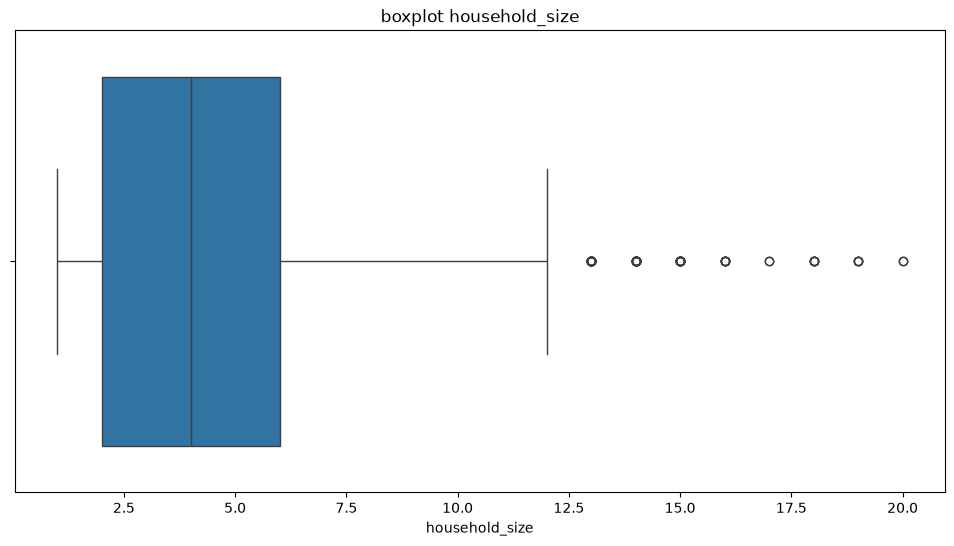

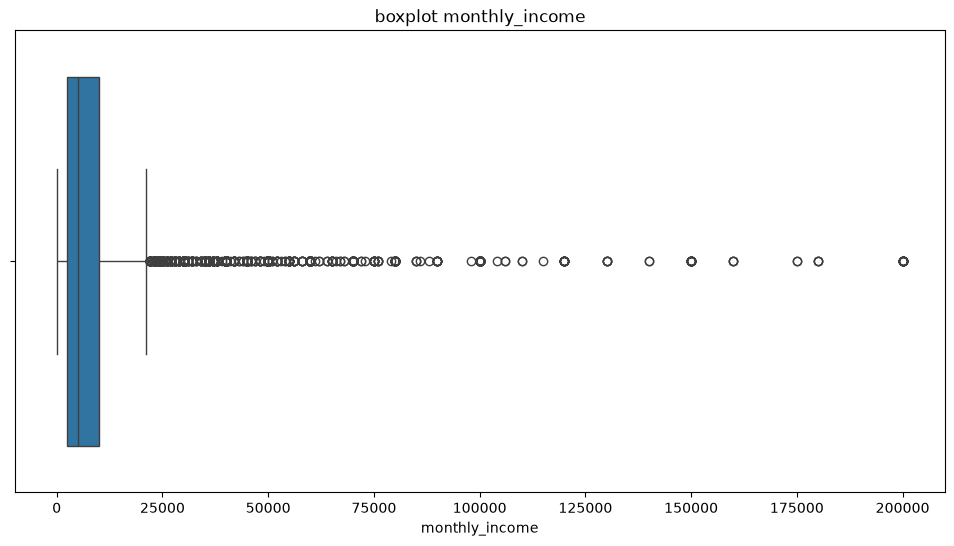

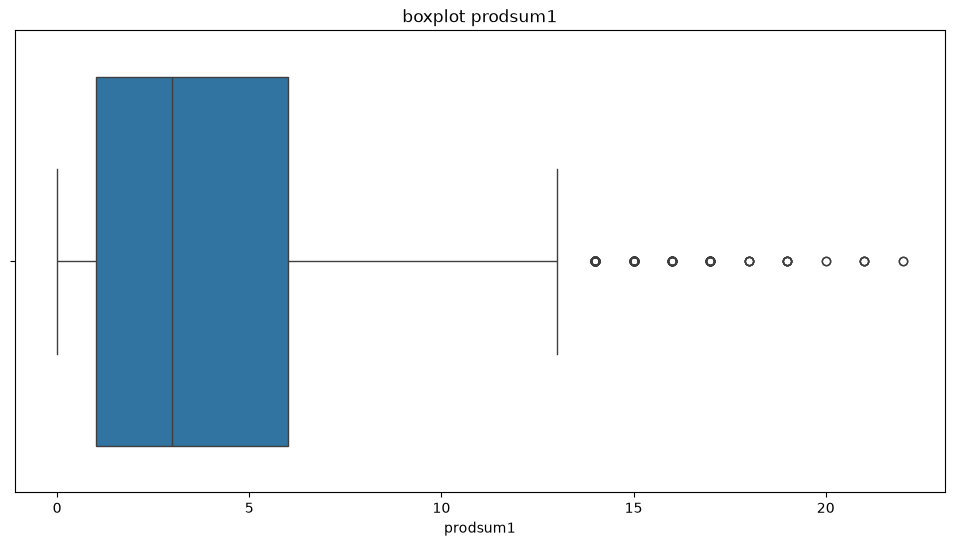

In [18]:
for col in numerical_cols:
    plt.figure(figsize=(12, 6))
    sns.boxplot(data=financial_df, x = col)
    plt.title(f"boxplot {col}")
    plt.show()

__Box plot__  
![boxplot]("https://miro.medium.com/v2/resize:fit:640/format:webp/1*JJSEEZ6cWNHJiYkb-y7lKg.png")

#### Cleaning the dataset

In [19]:
# converting column names to lower case
financial_df.columns = financial_df.columns.astype(str).str.strip().str.lower()
financial_df.columns

Index(['county', 'location_type', 'sex', 'age', 'household_size',
       'education_level', 'marital_status', 'monthly_income', 'savings_formal',
       'savings_informal', 'loan_formal', 'loan_informal', 'defaulted',
       'formal_service_use', 'mobile_money_access', 'barriers_mobile_money',
       'mobile_ownership_1', 'experienced_shock', 'nfhi_11', 'nfhi_12',
       'nfhi_13', 'accessto_13k_1month', 'not_difficult', 'financial_status',
       'fl_score', 'prodsum1', 'barriers_bank', 'has_disability'],
      dtype='str')

In [20]:
financial_df["education_level"].unique()

array(['Completed technical training after secondary school', '"None "',
       '"Primary completed"', '"Some secondary"',
       'Some technical training after secondary school',
       '"Secondary completed "', '"Some primary "',
       '"University completed "', '"Other (Specify) "', 'Some university',
       95, '"Refused to Answer (DO NOT READ OUT)"',
       '"Don\'t know (DO NOT READ OUT)"'], dtype=object)

In [21]:
mapping = {'Completed technical training after secondary school' : 'Technical training completed',
           '"None "' : 'None',
           '"Primary completed"' : 'Primary completed',
           '"Secondary completed "' : 'Secondary completed',
           '"Some secondary"' : 'Secondary incomplete',
           'Some technical training after secondary school' : 'Technical training incomplete',
           '"Some primary "' : 'Primary incomplete',
           '"University completed "' : 'University completed',
           'Some university' : 'University incomplete'}

financial_df["education_level"] = financial_df["education_level"].replace(mapping)

financial_df["education_level"].unique()

array(['Technical training completed', 'None', 'Primary completed',
       'Secondary incomplete', 'Technical training incomplete',
       'Secondary completed', 'Primary incomplete',
       'University completed', '"Other (Specify) "',
       'University incomplete', 95,
       '"Refused to Answer (DO NOT READ OUT)"',
       '"Don\'t know (DO NOT READ OUT)"'], dtype=object)

In [22]:
# Checking fro the proportion of eact category in education
(financial_df['education_level'].value_counts()/len(financial_df))*100

education_level
Secondary completed                      19.706770
Primary completed                        18.940156
Primary incomplete                       17.876479
None                                     14.747736
Secondary incomplete                     13.085142
Technical training completed              6.808490
University completed                      4.733841
Technical training incomplete             2.400460
University incomplete                     1.657803
"Refused to Answer (DO NOT READ OUT)"     0.014374
"Other (Specify) "                        0.009583
95                                        0.009583
"Don't know (DO NOT READ OUT)"            0.009583
Name: count, dtype: float64

In [23]:
# Dropping unecessary categories in educationla level column
cat_to_drop = ['"Refused to Answer (DO NOT READ OUT)"', '"Other (Specify) "', 95, '"Don\'t know (DO NOT READ OUT)"']
financial_df = financial_df[~financial_df['education_level'].isin(cat_to_drop)]

In [24]:
(financial_df['education_level'].value_counts()/len(financial_df))*100

education_level
Secondary completed              19.715272
Primary completed                18.948327
Primary incomplete               17.884191
None                             14.754098
Secondary incomplete             13.090787
Technical training completed      6.811427
University completed              4.735883
Technical training incomplete     2.401496
University incomplete             1.658518
Name: count, dtype: float64

__Cleaning categories in marital_status__

In [25]:
financial_df['marital_status'].unique()

<StringArray>
[       'Married/Living with partner',                 'Divorced/separated',
               'Single/Never Married',                            'Widowed',
     'Don't know   (DO NOT READ OUT)', 'Refused to Answer(DO NOT READ OUT)']
Length: 6, dtype: str

In [26]:
mapping = {'Married/Living with partner' : 'Married',
           'Divorced/separated' : 'Divorced',
           'Single/Never Married' : 'Single'}

financial_df['marital_status'] = financial_df['marital_status'].replace(mapping)

financial_df['marital_status'].unique()

<StringArray>
[                           'Married',                           'Divorced',
                             'Single',                            'Widowed',
     'Don't know   (DO NOT READ OUT)', 'Refused to Answer(DO NOT READ OUT)']
Length: 6, dtype: str

In [27]:
(financial_df['marital_status'].value_counts()/len(financial_df))*100

marital_status
Married                               54.783817
Single                                27.633976
Widowed                               10.703672
Divorced                               6.835394
Don't know   (DO NOT READ OUT)         0.023967
Refused to Answer(DO NOT READ OUT)     0.019174
Name: count, dtype: float64

In [28]:
cat_to_drop = ['Don\'t know   (DO NOT READ OUT)','Refused to Answer(DO NOT READ OUT)']
financial_df = financial_df[~financial_df['marital_status'].isin(cat_to_drop)]

__Cleaning barriers bank categorical entries__

In [29]:
mapping = {0 : 'None'}

financial_df['barriers_mobile_money'] = financial_df['barriers_mobile_money'].replace(mapping)

financial_df['barriers_mobile_money'].unique()

array(['None', 'Eligibility', 'Phone ownership', 'Line blocked', 'Other',
       'Affordability', 'Relevance/Suitability', 'Awareness',
       'Service quality', 'Trust'], dtype=object)

__Dropping duplicates__

In [30]:
financial_df = financial_df.drop_duplicates()

financial_df.duplicated().sum()

np.int64(0)

__Missing values__

In [31]:
(financial_df.isna().sum()/len(financial_df))*100

county                    0.000000
location_type             0.000000
sex                       0.000000
age                       0.000000
household_size            0.000000
education_level           0.000000
marital_status            0.000000
monthly_income            0.000000
savings_formal            0.000000
savings_informal          0.000000
loan_formal               0.000000
loan_informal             0.000000
defaulted                 0.000000
formal_service_use        0.000000
mobile_money_access       0.000000
barriers_mobile_money     0.000000
mobile_ownership_1        0.000000
experienced_shock         0.000000
nfhi_11                   0.000000
nfhi_12                   0.000000
nfhi_13                   0.000000
accessto_13k_1month       0.000000
not_difficult             0.000000
financial_status          0.000000
fl_score                  0.000000
prodsum1                  0.000000
barriers_bank            27.484651
has_disability            0.000000
dtype: float64

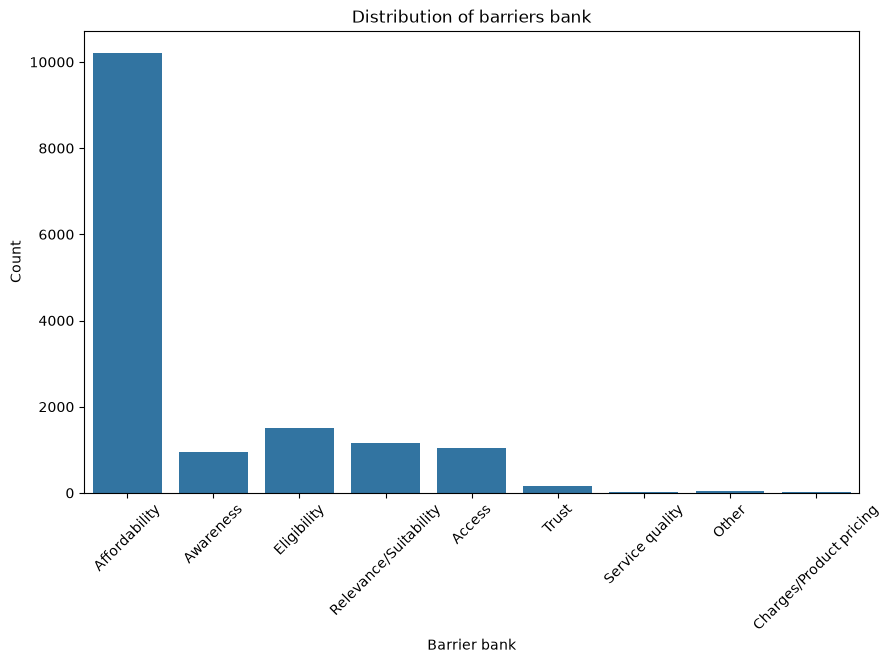

In [32]:
plt.figure(figsize=(10, 6))
sns.countplot(financial_df, x='barriers_bank')

plt.title('Distribution of barriers bank')
plt.ylabel('Count')
plt.xlabel('Barrier bank')
plt.xticks(rotation=45)

plt.show()

In [33]:
barriers_bank_mode = financial_df['barriers_bank'].mode()

print(barriers_bank_mode)

0    Affordability
Name: barriers_bank, dtype: str


In [34]:
financial_df = financial_df.fillna(value={'barriers_bank' : barriers_bank_mode})

financial_df.isna().sum()

county                      0
location_type               0
sex                         0
age                         0
household_size              0
education_level             0
marital_status              0
monthly_income              0
savings_formal              0
savings_informal            0
loan_formal                 0
loan_informal               0
defaulted                   0
formal_service_use          0
mobile_money_access         0
barriers_mobile_money       0
mobile_ownership_1          0
experienced_shock           0
nfhi_11                     0
nfhi_12                     0
nfhi_13                     0
accessto_13k_1month         0
not_difficult               0
financial_status            0
fl_score                    0
prodsum1                    0
barriers_bank            5729
has_disability              0
dtype: int64

In [35]:
financial_df['barriers_bank'] = np.where(financial_df['barriers_bank'].isnull(), barriers_bank_mode, financial_df['barriers_bank'])

financial_df.isnull().sum()

county                   0
location_type            0
sex                      0
age                      0
household_size           0
education_level          0
marital_status           0
monthly_income           0
savings_formal           0
savings_informal         0
loan_formal              0
loan_informal            0
defaulted                0
formal_service_use       0
mobile_money_access      0
barriers_mobile_money    0
mobile_ownership_1       0
experienced_shock        0
nfhi_11                  0
nfhi_12                  0
nfhi_13                  0
accessto_13k_1month      0
not_difficult            0
financial_status         0
fl_score                 0
prodsum1                 0
barriers_bank            0
has_disability           0
dtype: int64

#### Exploratory Data Analysis(EDA) and Hypothesis Testing

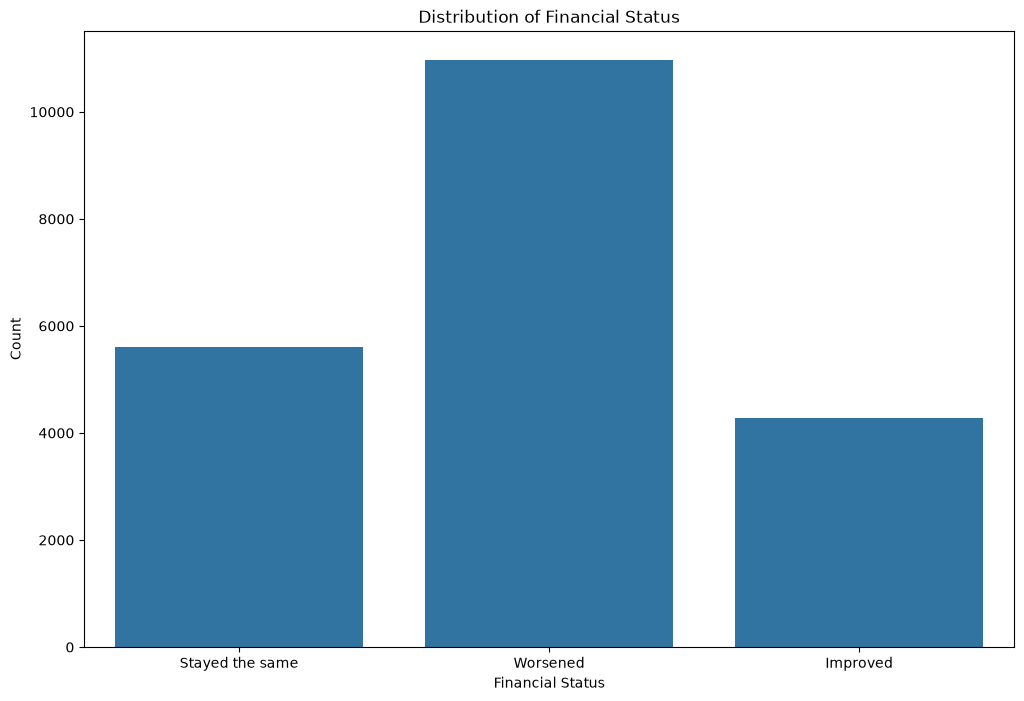

In [36]:
plt.figure(figsize=(12, 8))
sns.countplot(financial_df, x='financial_status')

plt.title('Distribution of Financial Status')
plt.ylabel('Count')
plt.xlabel('Financial Status')
plt.show()


__percentage of formal savings in rural vs urban__

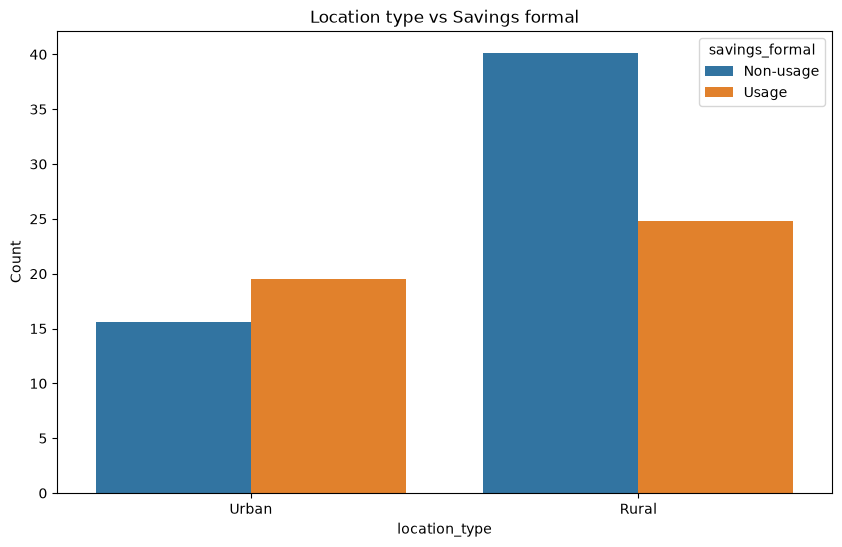

In [37]:
plt.figure(figsize=(10, 6))
sns.countplot(financial_df, x='location_type', hue='savings_formal', stat='percent')

plt.title('Location type vs Savings formal')
plt.ylabel('Count')
plt.xlabel('location_type')
plt.show()

__can we find the education levels for people living with disabilities__

In [38]:
disabled = financial_df[financial_df['has_disability']=='With Disability']

disabled

,county,location_type,sex,age,household_size,education_level,marital_status,monthly_income,savings_formal,savings_informal,...,nfhi_11,nfhi_12,nfhi_13,accessto_13k_1month,not_difficult,financial_status,fl_score,prodsum1,barriers_bank,has_disability
15,Homabay,Rural,Female,46-55,3,Primary incomplete,Married,5000,Non-usage,Non-usage,...,Yes,No,No,No,No,Worsened,One correct,3,Affordability,With Disability
35,Nairobi City,Urban,Male,Above 55,3,University completed,Married,5000,Usage,Non-usage,...,Yes,Yes,Yes,Yes,No,Improved,Two correct,11,Affordability,With Disability
75,Marsabit,Rural,Female,26-35,5,None,Married,15000,Usage,Non-usage,...,No,No,Yes,No,No,Worsened,None correct,2,Trust,With Disability
82,Laikipia,Rural,Male,36-45,3,Secondary incomplete,Married,2400,Usage,Non-usage,...,Yes,Yes,No,Yes,Yes,Improved,All correct,3,Affordability,With Disability
97,Migori,Rural,Female,46-55,2,Primary incomplete,Married,2000,Non-usage,Non-usage,...,No,No,Yes,No,No,Worsened,Two correct,1,Affordability,With Disability
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20835,Vihiga,Rural,Male,18-25,7,Secondary incomplete,Single,17000,Non-usage,Non-usage,...,Yes,No,Yes,No,No,Improved,One correct,0,Eligibility,With Disability
20838,Vihiga,Rural,Female,Above 55,3,Primary completed,Widowed,100,Non-usage,Non-usage,...,No,Yes,No,No,No,Worsened,Two correct,1,Affordability,With Disability
20839,Lamu,Rural,Male,36-45,5,Primary incomplete,Single,3000,Non-usage,Non-usage,...,Yes,No,Yes,No,No,Worsened,All correct,0,Affordability,With Disability
20856,Laikipia,Rural,Female,36-45,3,Technical training incomplete,Divorced,5000,Non-usage,Usage,...,No,No,No,Yes,Yes,Improved,Two correct,7,Affordability,With Disability


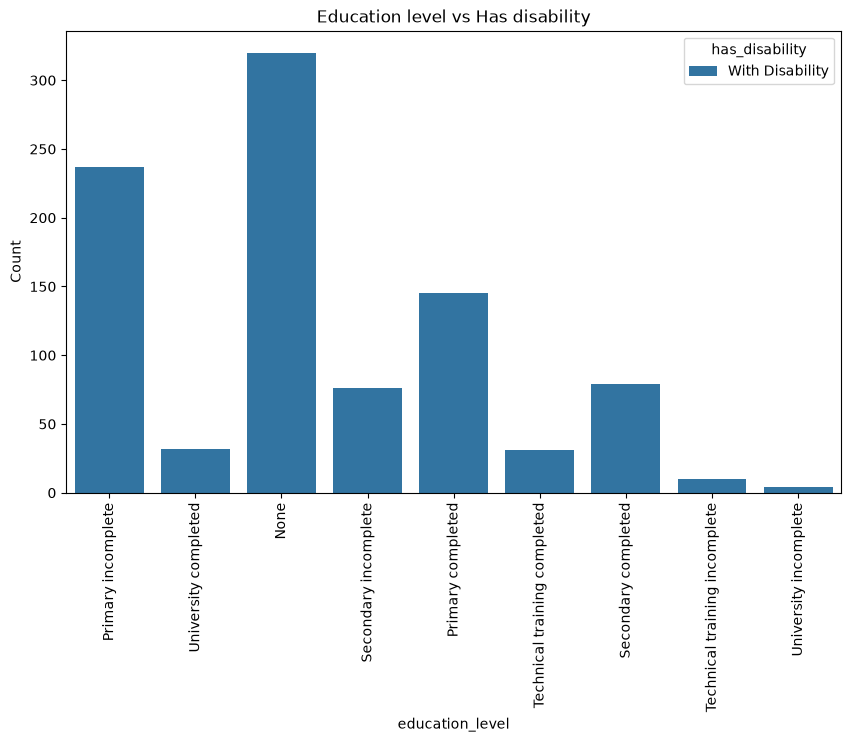

In [39]:
plt.figure(figsize=(10, 6))
sns.countplot(disabled, x='education_level', hue='has_disability')

plt.title('Education level vs Has disability')
plt.ylabel('Count')
plt.xlabel('education_level')
plt.xticks(rotation=90)
plt.show()

__can we find the distribution of household_size  based of the location_type__

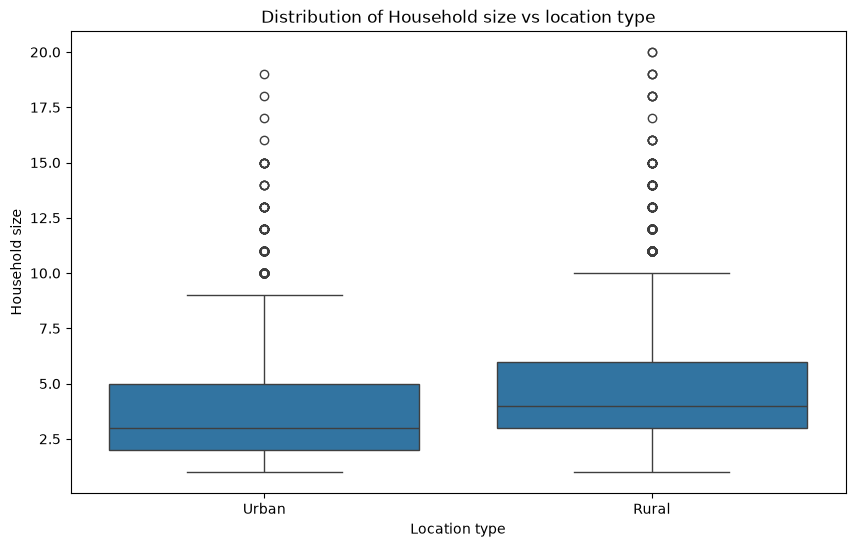

In [40]:
plt.figure(figsize=(10, 6))
sns.boxplot(financial_df, x='location_type', y='household_size')

plt.title('Distribution of Household size vs location type')
plt.ylabel('Household size')
plt.xlabel('Location type')
plt.show()


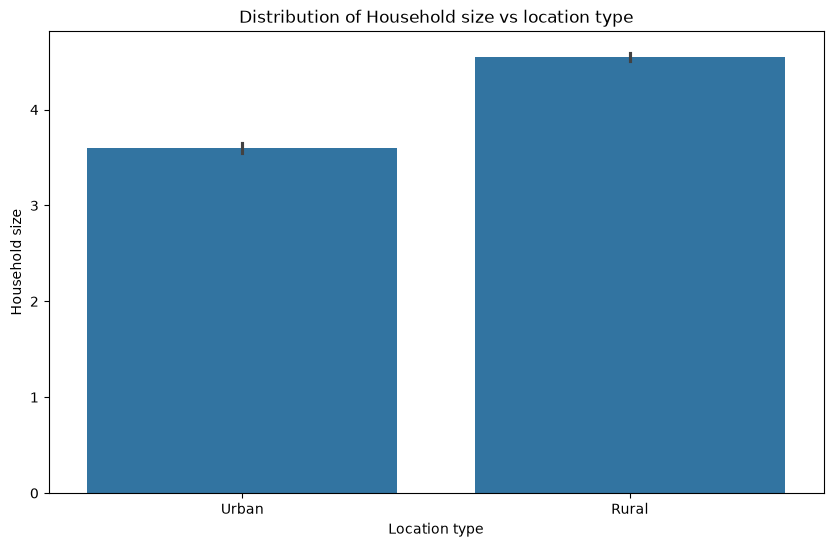

In [41]:
plt.figure(figsize=(10, 6))
sns.barplot(financial_df, x='location_type', y='household_size')

plt.title('Distribution of Household size vs location type')
plt.ylabel('Household size')
plt.xlabel('Location type')
plt.show()

__FEATURE SELECTION USING HYPOTHESIS TESTING:__

In [42]:
# Testing relationship between categorical columns and target(categorical)
#  We use Chi square test of independence.

categorical_cols


['county',
 'location_type',
 'Sex',
 'Age',
 'education_level',
 'marital_status',
 'Savings_formal',
 'Savings_informal',
 'Loan_formal',
 'Loan_informal',
 'defaulted',
 'formal_service_use',
 'mobile_money_access',
 'barriers_mobile_money',
 'mobile_ownership_1',
 'experienced_shock',
 'nfhi_11',
 'nfhi_12',
 'nfhi_13',
 'accessto_13k_1month',
 'not_difficult',
 'financial_status',
 'fl_score',
 'barriers_bank',
 'has_disability']

In [43]:
cat_cols= financial_df.select_dtypes(include=['str','object']).columns.to_list()
cat_cols

['county',
 'location_type',
 'sex',
 'age',
 'education_level',
 'marital_status',
 'savings_formal',
 'savings_informal',
 'loan_formal',
 'loan_informal',
 'defaulted',
 'formal_service_use',
 'mobile_money_access',
 'barriers_mobile_money',
 'mobile_ownership_1',
 'experienced_shock',
 'nfhi_11',
 'nfhi_12',
 'nfhi_13',
 'accessto_13k_1month',
 'not_difficult',
 'financial_status',
 'fl_score',
 'barriers_bank',
 'has_disability']

In [44]:
# Drop target

cat_cols.remove('financial_status')


In [45]:
for col in cat_cols:
    H0 = f" No relationship between financial status and {col}"
    H1 =f"There is a relationship between financial status and {col}"

    alpha = 0.05 #level of significance

    contigency_table = pd.crosstab(financial_df[col],financial_df['financial_status'])
    chi2_stats, p_value, dof, expected = chi2_contingency(contigency_table)

    if p_value <= alpha:
        print(f"Reject the Null hypothesis that:'{H0}'")
    else:
        print(f"Fail to reject the Null hypothesis that:'{H0}'")




Reject the Null hypothesis that:' No relationship between financial status and county'
Reject the Null hypothesis that:' No relationship between financial status and location_type'
Reject the Null hypothesis that:' No relationship between financial status and sex'
Reject the Null hypothesis that:' No relationship between financial status and age'
Reject the Null hypothesis that:' No relationship between financial status and education_level'
Reject the Null hypothesis that:' No relationship between financial status and marital_status'
Reject the Null hypothesis that:' No relationship between financial status and savings_formal'
Reject the Null hypothesis that:' No relationship between financial status and savings_informal'
Reject the Null hypothesis that:' No relationship between financial status and loan_formal'
Reject the Null hypothesis that:' No relationship between financial status and loan_informal'
Reject the Null hypothesis that:' No relationship between financial status and def

In [46]:
print(contigency_table)

financial_status    Improved  Stayed the same  Worsened
has_disability                                         
With Disability           94              266       574
Without Disability      4185             5341     10388


In [47]:
print(expected)

[[  191.70117038   251.19618189   491.10264774]
 [ 4087.29882962  5355.80381811 10470.89735226]]


$E = \frac{\text{Row Total} \times \text{Column Total}}{\text{Grand Total}}$

In [48]:
# Calculate Expected values (scipy does this automatically)

row_total = 94 + 266 + 574
column_total = 94 + 4186
grand_total = 94 + 4186 + 266 + 5341 + 574 + 10396

expected_vals = (row_total * column_total)/grand_total

print(expected_vals)


191.6632305700724


_Numerical Vs target hypothesis test:(target is categorical)_

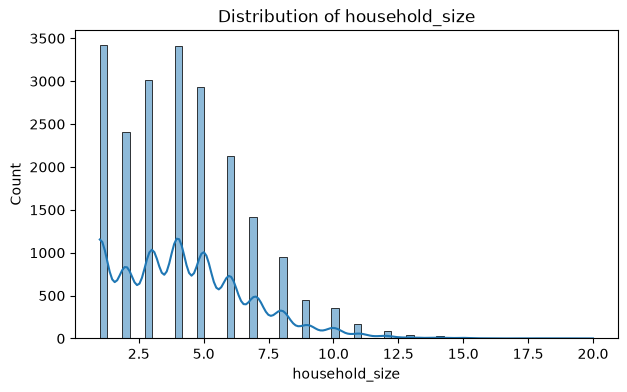

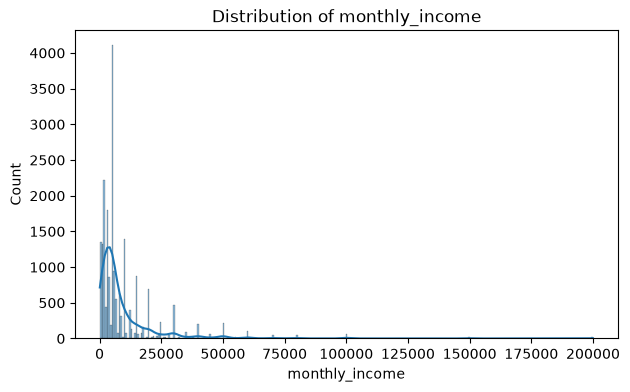

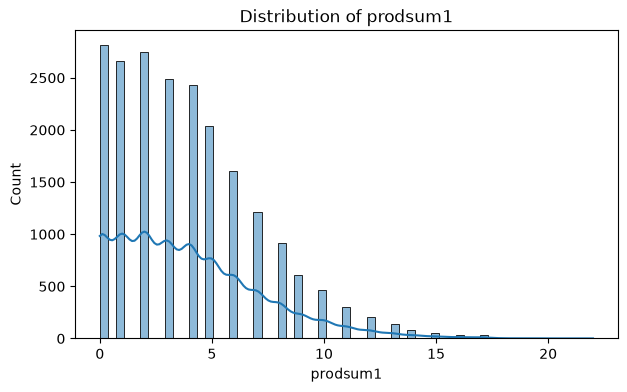

In [49]:
# Check for normality of numerical column & homogenity of variance

for col in numerical_cols:
    plt.figure(figsize=(7,4))
    sns.histplot(financial_df, x=col, kde=True)
    plt.title(f"Distribution of {col}")
    plt.show()
    




In [50]:
# Check for homogenity of variance:

for col in numerical_cols:
    print(financial_df.groupby("financial_status")[col].var())


financial_status
Improved           6.467929
Stayed the same    6.898233
Worsened           5.927000
Name: household_size, dtype: float64
financial_status
Improved           4.348968e+08
Stayed the same    1.687126e+08
Worsened           1.856890e+08
Name: monthly_income, dtype: float64
financial_status
Improved           12.176858
Stayed the same     9.802104
Worsened            9.739629
Name: prodsum1, dtype: float64


In [51]:
for col in numerical_cols:
    H0 = f"No difference in distribution of {col} across financial statuses"
    H1 = f"There is a difference in distribution of atleast one {col} across financial statuses"

    alpha = 0.05

    num_groups = [group[col].values for name, group in financial_df.groupby('financial_status')]
    hstat, p_value = kruskal(*num_groups)

    if p_value <= alpha:
        print(f"Reject the null hypothesis : '{H0}'")
    else:
        print(f"Fail to reject null hypothesis :'{H0}'") # Drop feature if you fail to reject null hypothesis
        

Reject the null hypothesis : 'No difference in distribution of household_size across financial statuses'
Reject the null hypothesis : 'No difference in distribution of monthly_income across financial statuses'
Reject the null hypothesis : 'No difference in distribution of prodsum1 across financial statuses'


__Correlation Analysis:__

                household_size  monthly_income  prodsum1
household_size        1.000000       -0.116456 -0.156941
monthly_income       -0.116456        1.000000  0.433303
prodsum1             -0.156941        0.433303  1.000000


<Axes: >

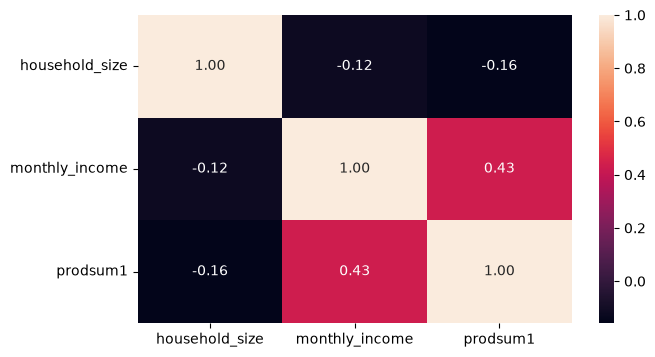

In [52]:
# Numerical Vs Numerical testing ; Correlation analysis

correlation = financial_df[numerical_cols].corr(method="spearman")

print (correlation)

# Plot the correlation heatmap (visual)

plt.figure(figsize=(7,4))
sns.heatmap(correlation, annot=True, fmt=".2f")


### Prepare the data for modelling:

In [53]:
# Seperate your target and your features:

X = financial_df.drop(columns=['financial_status'])
y = financial_df['financial_status']

# Split your data into 80% training and 20& testing subsets.

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y) # stratify ensures all classes are represented equally during the splitting

print(X_train.shape)
print(financial_df.shape)

(16678, 27)
(20848, 28)


In [54]:
X.columns

Index(['county', 'location_type', 'sex', 'age', 'household_size',
       'education_level', 'marital_status', 'monthly_income', 'savings_formal',
       'savings_informal', 'loan_formal', 'loan_informal', 'defaulted',
       'formal_service_use', 'mobile_money_access', 'barriers_mobile_money',
       'mobile_ownership_1', 'experienced_shock', 'nfhi_11', 'nfhi_12',
       'nfhi_13', 'accessto_13k_1month', 'not_difficult', 'fl_score',
       'prodsum1', 'barriers_bank', 'has_disability'],
      dtype='str')

In [55]:
X_train.head(10)

,county,location_type,sex,age,household_size,education_level,marital_status,monthly_income,savings_formal,savings_informal,...,experienced_shock,nfhi_11,nfhi_12,nfhi_13,accessto_13k_1month,not_difficult,fl_score,prodsum1,barriers_bank,has_disability
11494,Murang'a,Rural,Male,26-35,4,None,Single,5000,Non-usage,Non-usage,...,Yes,No,No,No,No,No,One correct,0,Affordability,With Disability
18809,Kwale,Rural,Female,26-35,5,Primary completed,Married,5000,Usage,Non-usage,...,Yes,No,No,No,No,No,One correct,3,Affordability,Without Disability
16894,Nakuru,Urban,Female,18-25,1,Secondary incomplete,Single,40000,Usage,Non-usage,...,Yes,No,No,No,No,No,All correct,6,Affordability,Without Disability
13083,Mandera,Rural,Female,16-17,8,Secondary incomplete,Single,5000,Non-usage,Non-usage,...,No,Yes,Yes,Yes,No,No,All correct,0,Affordability,Without Disability
1315,Garissa,Urban,Female,18-25,2,Secondary completed,Married,6000,Non-usage,Usage,...,Yes,No,No,No,No,No,All correct,3,Affordability,Without Disability
14798,West Pokot,Rural,Male,18-25,10,Primary incomplete,Single,1700,Non-usage,Non-usage,...,Yes,No,Yes,Yes,No,No,Two correct,0,Access,Without Disability
17380,Busia,Rural,Male,36-45,5,Secondary completed,Married,5000,Usage,Non-usage,...,Yes,Yes,Yes,Yes,No,No,Two correct,3,Affordability,Without Disability
1739,Homabay,Urban,Male,18-25,3,Secondary completed,Married,12000,Non-usage,Non-usage,...,Yes,No,No,No,Yes,No,Two correct,2,Affordability,Without Disability
19038,West Pokot,Rural,Male,26-35,5,Secondary incomplete,Single,15000,Usage,Usage,...,No,No,No,No,Yes,Yes,Two correct,5,Relevance/Suitability,Without Disability
9177,Kwale,Rural,Male,18-25,4,Primary incomplete,Divorced,5000,Usage,Usage,...,Yes,No,Yes,No,Yes,No,All correct,11,Affordability,Without Disability


In [56]:
X_train.columns

Index(['county', 'location_type', 'sex', 'age', 'household_size',
       'education_level', 'marital_status', 'monthly_income', 'savings_formal',
       'savings_informal', 'loan_formal', 'loan_informal', 'defaulted',
       'formal_service_use', 'mobile_money_access', 'barriers_mobile_money',
       'mobile_ownership_1', 'experienced_shock', 'nfhi_11', 'nfhi_12',
       'nfhi_13', 'accessto_13k_1month', 'not_difficult', 'fl_score',
       'prodsum1', 'barriers_bank', 'has_disability'],
      dtype='str')

In [57]:
print(cat_cols)


['county', 'location_type', 'sex', 'age', 'education_level', 'marital_status', 'savings_formal', 'savings_informal', 'loan_formal', 'loan_informal', 'defaulted', 'formal_service_use', 'mobile_money_access', 'barriers_mobile_money', 'mobile_ownership_1', 'experienced_shock', 'nfhi_11', 'nfhi_12', 'nfhi_13', 'accessto_13k_1month', 'not_difficult', 'fl_score', 'barriers_bank', 'has_disability']


### Perform Preprocessing : Scaling and Encoding

__Encode your target__ : target is categorical column 'financial_status.
__Encode your features__

In [58]:
for col in cat_cols:
    print("="*25)
    print(f"***Column Name:{col}***")
    print("="*25)
    print(financial_df[col].unique())

***Column Name:county***
<StringArray>
[        'Garissa',           'Busia',          'Kiambu',        'Murang'a',
          'Kilifi',            'Meru',          'Kisumu',         'Baringo',
          'Isiolo',            'Embu',         'Mombasa', 'Elgeyo-Marakwet',
         'Homabay',          'Migori',           'Siaya',      'West Pokot',
           'Nyeri',           'Bomet',         'Makueni',     'Uasin Gishu',
         'Bungoma',          'Nakuru',        'Kakamega',           'Kwale',
           'Kitui',         'Mandera',    'Nairobi City',        'Machakos',
   'Tharaka-Nithi',       'Nyandarua',        'Marsabit',       'Kirinyaga',
         'Kericho',           'Kisii',    'Taita-Taveta',          'Vihiga',
     'Trans Nzoia',           'Narok',         'Kajiado',        'Laikipia',
           'Nandi',            'Lamu',         'Turkana',         'Samburu',
      'Tana River',           'Wajir',         'Nyamira']
Length: 47, dtype: str
***Column Name:location_type***
<

In [59]:
numerical_cols

['household_size', 'monthly_income', 'prodsum1']

In [60]:
# Encode your target column(y) : 

l_encoder = LabelEncoder()
y_train_encoded = l_encoder.fit_transform(y_train)
y_test_encoded = l_encoder.transform(y_test)


In [61]:
financial_df['age'].unique()

<StringArray>
['26-35', 'Above 55', '18-25', '36-45', '46-55', '16-17']
Length: 6, dtype: str

In [62]:
X_train.columns.to_list()


['county',
 'location_type',
 'sex',
 'age',
 'household_size',
 'education_level',
 'marital_status',
 'monthly_income',
 'savings_formal',
 'savings_informal',
 'loan_formal',
 'loan_informal',
 'defaulted',
 'formal_service_use',
 'mobile_money_access',
 'barriers_mobile_money',
 'mobile_ownership_1',
 'experienced_shock',
 'nfhi_11',
 'nfhi_12',
 'nfhi_13',
 'accessto_13k_1month',
 'not_difficult',
 'fl_score',
 'prodsum1',
 'barriers_bank',
 'has_disability']

In [63]:
#Encode your categorical columns column by column:

# Encode age column (ordinal encoder)

age_order = ['16-17','18-25','26-35','36-45','46-55','Above 55'] #smallest to largest

ord_encoder = OrdinalEncoder(categories=[age_order])

X_train['age'] = ord_encoder.fit_transform(X_train[['age']])
X_test['age'] = ord_encoder.transform(X_test[['age']])


In [64]:
X_train.head(10)

,county,location_type,sex,age,household_size,education_level,marital_status,monthly_income,savings_formal,savings_informal,...,experienced_shock,nfhi_11,nfhi_12,nfhi_13,accessto_13k_1month,not_difficult,fl_score,prodsum1,barriers_bank,has_disability
11494,Murang'a,Rural,Male,2.0,4,None,Single,5000,Non-usage,Non-usage,...,Yes,No,No,No,No,No,One correct,0,Affordability,With Disability
18809,Kwale,Rural,Female,2.0,5,Primary completed,Married,5000,Usage,Non-usage,...,Yes,No,No,No,No,No,One correct,3,Affordability,Without Disability
16894,Nakuru,Urban,Female,1.0,1,Secondary incomplete,Single,40000,Usage,Non-usage,...,Yes,No,No,No,No,No,All correct,6,Affordability,Without Disability
13083,Mandera,Rural,Female,0.0,8,Secondary incomplete,Single,5000,Non-usage,Non-usage,...,No,Yes,Yes,Yes,No,No,All correct,0,Affordability,Without Disability
1315,Garissa,Urban,Female,1.0,2,Secondary completed,Married,6000,Non-usage,Usage,...,Yes,No,No,No,No,No,All correct,3,Affordability,Without Disability
14798,West Pokot,Rural,Male,1.0,10,Primary incomplete,Single,1700,Non-usage,Non-usage,...,Yes,No,Yes,Yes,No,No,Two correct,0,Access,Without Disability
17380,Busia,Rural,Male,3.0,5,Secondary completed,Married,5000,Usage,Non-usage,...,Yes,Yes,Yes,Yes,No,No,Two correct,3,Affordability,Without Disability
1739,Homabay,Urban,Male,1.0,3,Secondary completed,Married,12000,Non-usage,Non-usage,...,Yes,No,No,No,Yes,No,Two correct,2,Affordability,Without Disability
19038,West Pokot,Rural,Male,2.0,5,Secondary incomplete,Single,15000,Usage,Usage,...,No,No,No,No,Yes,Yes,Two correct,5,Relevance/Suitability,Without Disability
9177,Kwale,Rural,Male,1.0,4,Primary incomplete,Divorced,5000,Usage,Usage,...,Yes,No,Yes,No,Yes,No,All correct,11,Affordability,Without Disability


In [65]:
cat_cols2 = cat_cols.remove('age')
cat_cols2

In [66]:
# Onehot encode the other categorical columns

X_train = pd.get_dummies(X_train, columns=cat_cols2, drop_first=True, dtype='int')
X_test = pd.get_dummies(X_test, columns=cat_cols2, drop_first=True, dtype='int')




# LOGISTIC REGRESSION : PROBABILITY PREDICTION MODEL

In [67]:
# Instantiate the model

logistic_model = LogisticRegression(max_iter=1000)

#Fit the model

logistic_model.fit(X_train, y_train_encoded)

# Make predictions

y_pred = logistic_model.predict(X_test)



c:\Users\USER\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


# Decision tree Model:

In [68]:
# Instantiate the model

decision_model = DecisionTreeClassifier(max_depth=10)

# Train the model

decision_model.fit(X_train, y_train_encoded)

#Make prediction

y_pred_tree = decision_model.predict(X_test)

#Evaluate Model

print("Decision tree classification report:\n",classification_report(y_test_encoded,y_pred_tree, target_names=l_encoder.classes_))


Decision tree classification report:
                  precision    recall  f1-score   support

       Improved       0.41      0.27      0.32       856
Stayed the same       0.41      0.20      0.27      1121
       Worsened       0.60      0.83      0.69      2193

       accuracy                           0.55      4170
      macro avg       0.47      0.43      0.43      4170
   weighted avg       0.51      0.55      0.50      4170



In [69]:
print(len(X_test))
print(856+1121+2193)

4170
4170


# KNN NEIGHBOURS :

In [70]:
# Instantiate the model

knn_model = KNeighborsClassifier(n_neighbors=7,metric='euclidean')

# Fit the model

knn_model.fit(X_train, y_train_encoded)

# Make predictions

knn_pred = knn_model.predict(X_test)

#Evaluate Model

print("KNN Classification report:\n", classification_report(y_test_encoded, knn_pred, target_names=l_encoder.classes_))




KNN Classification report:
                  precision    recall  f1-score   support

       Improved       0.36      0.30      0.33       856
Stayed the same       0.36      0.30      0.33      1121
       Worsened       0.60      0.69      0.64      2193

       accuracy                           0.51      4170
      macro avg       0.44      0.43      0.43      4170
   weighted avg       0.49      0.51      0.49      4170



In [71]:
# Instantiate the model

knn_model = KNeighborsClassifier(n_neighbors=7,metric='manhattan')

# Fit the model

knn_model.fit(X_train, y_train_encoded)

# Make predictions

knn_pred = knn_model.predict(X_test)

#Evaluate Model

print("KNN Classification Manhattan report:\n", classification_report(y_test_encoded, knn_pred, target_names=l_encoder.classes_))




KNN Classification Manhattan report:
                  precision    recall  f1-score   support

       Improved       0.35      0.30      0.32       856
Stayed the same       0.34      0.28      0.31      1121
       Worsened       0.60      0.69      0.64      2193

       accuracy                           0.50      4170
      macro avg       0.43      0.42      0.42      4170
   weighted avg       0.48      0.50      0.49      4170



In [72]:
# Instantiate the model

knn_model = KNeighborsClassifier(n_neighbors=7,metric='minkowski')

# Fit the model

knn_model.fit(X_train, y_train_encoded)

# Make predictions

knn_pred = knn_model.predict(X_test)

#Evaluate Model

print("KNN Classification report:\n", classification_report(y_test_encoded, knn_pred, target_names=l_encoder.classes_))




KNN Classification report:
                  precision    recall  f1-score   support

       Improved       0.36      0.30      0.33       856
Stayed the same       0.36      0.30      0.33      1121
       Worsened       0.60      0.69      0.64      2193

       accuracy                           0.51      4170
      macro avg       0.44      0.43      0.43      4170
   weighted avg       0.49      0.51      0.49      4170



# ENSEMBLE MODELS:
 ## Bagging : 
 - Combines multiple models using different samples of the dataset to train and make more accurate predictions.
 - Regression : Uses the average 
 - Classification : Majority vote
 

In [73]:
# Instatiate the model

random_forest = RandomForestClassifier(n_estimators=1000, max_depth=4)

#Train the model

random_forest.fit(X_train, y_train_encoded)

# Make predictions

rf_pred = random_forest.predict(X_test)

# Evaluate the model

print("Random Forest Classification report:\n", classification_report(y_test_encoded, rf_pred,target_names=l_encoder.classes_))

Random Forest Classification report:
                  precision    recall  f1-score   support

       Improved       0.00      0.00      0.00       856
Stayed the same       0.49      0.05      0.09      1121
       Worsened       0.54      0.99      0.69      2193

       accuracy                           0.53      4170
      macro avg       0.34      0.35      0.26      4170
   weighted avg       0.41      0.53      0.39      4170



c:\Users\USER\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\USER\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\USER\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

## Boosting Ensemble Methods:

In [ ]:
# Gradient Boosting 

gb_model = GradientBoostingClassifier(n_estimators=200,max_depth=4)

gb_model.fit(X_train, y_train_encoded)

gb_pred = gb_model.predict(X_test)

print("Gradient Boosting Classification report:\n", classification_report(y_test_encoded, gb_pred,target_names=l_encoder.classes_))



Gradient Boosting Classification report:
                  precision    recall  f1-score   support

       Improved       0.48      0.31      0.38       856
Stayed the same       0.47      0.23      0.31      1121
       Worsened       0.62      0.86      0.72      2193

       accuracy                           0.58      4170
      macro avg       0.52      0.47      0.47      4170
   weighted avg       0.55      0.58      0.54      4170



## XGBoost Model:


In [74]:

xgb_model = XGBClassifier(n_estimators=200, max_depth=4)

xgb_model.fit(X_train, y_train_encoded)

xgb_pred = xgb_model.predict(X_test)

print("XGBoost classification report:\n", classification_report(y_test_encoded, xgb_pred, target_names=l_encoder.classes_))


XGBoost classification report:
                  precision    recall  f1-score   support

       Improved       0.46      0.32      0.38       856
Stayed the same       0.47      0.27      0.34      1121
       Worsened       0.62      0.84      0.71      2193

       accuracy                           0.58      4170
      macro avg       0.52      0.47      0.48      4170
   weighted avg       0.55      0.58      0.55      4170



# SUPPORT VECTOR MACHINES:



In [ ]:
#Instantiate the SVM model
svm_model = SVC(kernel='rbf', gamma='auto')

# Train/fit the model

svm_model.fit(X_train, y_train_encoded)

# Make prediction

svm_pred = svm_model.predict(X_test)

# Evaluate the model

print("SVM Classification report:\n", classification_report(y_test_encoded, svm_pred,target_names=l_encoder.classes_))